In [ ]:
**Problem 2c**

In [11]:
#break this up a little bit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("big12.csv")
data["date"] = pd.to_datetime(data["date"])

teams = sorted(set(data["home"]) | set(data["away"]))
team_index = {team: i for i, team in enumerate(teams)}

m = len(teams)
w = 1

#functions
def h_value(S, T):
    x = (S + 1) / (S + T + 2)

    return (
        0.5
        + 0.5
        * np.sign(x - 0.5)
        * np.sqrt(abs(2 * x - 1))
    )

#flat
def flat_prior():
    prior = np.full((m, m), 0.5)
    np.fill_diagonal(prior, 0)

    return prior

#last season
def last_season_prior():
    values = [[[] for _ in range(m)] for _ in range(m)]

    games = data[
        (data["season"] == 2025)
        & (data["completed"] == 1)
    ]

    for _, game in games.iterrows():
        home = team_index[game["home"]]
        away = team_index[game["away"]]

        h_home = h_value(
            game["home_pts"],
            game["away_pts"]
        )

        values[home][away].append(h_home)
        values[away][home].append(1 - h_home)

    prior = np.full((m, m), 0.5)

    for i in range(m):
        for j in range(m):
            if i != j and len(values[i][j]) > 0:
                prior[i, j] = np.mean(values[i][j])

    np.fill_diagonal(prior, 0)

    return prior

#record prior, based on record from last year.
def record_prior():
    wins = np.zeros(m)
    games_played = np.zeros(m)

    games = data[
        (data["season"] == 2025)
        & (data["completed"] == 1)
    ]

    for _, game in games.iterrows():
        home = team_index[game["home"]]
        away = team_index[game["away"]]

        games_played[home] += 1
        games_played[away] += 1

        if game["home_pts"] > game["away_pts"]:
            wins[home] += 1
        elif game["away_pts"] > game["home_pts"]:
            wins[away] += 1
        else:
            wins[home] += 0.5
            wins[away] += 0.5

    strength = (wins + 1) / (games_played + 2)

    prior = (
        strength[:, None]
        / (strength[:, None] + strength[None, :])
    )

    np.fill_diagonal(prior, 0)

    return prior


def build_A(prior):
    game_scores = np.zeros((m, m))
    games_played = np.zeros(m)

    games = data[
        (data["season"] == 2026)
        & (data["completed"] == 1)
        & (data["date"] < "2026-10-10")
    ]

    for _, game in games.iterrows():
        home = team_index[game["home"]]
        away = team_index[game["away"]]

        h_home = h_value(
            game["home_pts"],
            game["away_pts"]
        )

        game_scores[home, away] += h_home
        game_scores[away, home] += 1 - h_home

        games_played[home] += 1
        games_played[away] += 1

    denominator = (
        games_played[:, None]
        + w * (m - 1)
    )

    A = (
        game_scores + w * prior
    ) / denominator

    np.fill_diagonal(A, 0)

    return A


def power_iteration(A):
    r = np.ones(m) / m

    while True:
        new_r = A @ r
        new_r = new_r / new_r.sum()

        if np.max(np.abs(new_r - r)) < 1e-12:
            return new_r

        r = new_r


def analyze_prior(name, prior):
    A = build_A(prior)
    r = power_iteration(A)

    eigenvalues = np.linalg.eigvals(A)

    order = np.argsort(
        np.abs(eigenvalues)
    )[::-1]

    lambda_star = eigenvalues[order[0]].real

    ratio = abs(
        eigenvalues[order[1]]
        / eigenvalues[order[0]]
    )

    print(f"\n{name}")
    print(f"lambda* = {lambda_star:.6f}")
    print(f"|lambda2 / lambda*| = {ratio:.6f}")

    ranking = pd.DataFrame({
        "Team": teams,
        "Ranking": r
    })

    ranking = ranking.sort_values(
        "Ranking",
        ascending=False
    ).reset_index(drop=True)

    ranking.index += 1
    print(ranking.to_string())

    return {
        "A": A,
        "r": r,
        "lambda_star": lambda_star,
        "ratio": ratio
    }


priors = {
    "Flat Prior": flat_prior(),
    "2025 H2H Prior": last_season_prior(),
    "2025 Record Prior": record_prior()
}

results = {}

for name, prior in priors.items():
    results[name] = analyze_prior(name, prior)


Flat Prior
lambda* = 0.499233
|lambda2 / lambda*| = 0.158985
              Team   Ranking
1           Baylor  0.066326
2              BYU  0.065808
3       Texas Tech  0.065561
4             Utah  0.064429
5   Oklahoma State  0.064241
6          Houston  0.063684
7          Arizona  0.063588
8              UCF  0.062385
9    Arizona State  0.061555
10    Kansas State  0.061447
11      Iowa State  0.061288
12          Kansas  0.061072
13      Cincinnati  0.060784
14   West Virginia  0.060194
15             TCU  0.059333
16        Colorado  0.058305

2025 H2H Prior
lambda* = 0.481875
|lambda2 / lambda*| = 0.159949
              Team   Ranking
1       Texas Tech  0.086883
2              BYU  0.077280
3             Utah  0.076353
4          Arizona  0.073203
5          Houston  0.067711
6       Iowa State  0.065379
7     Kansas State  0.064639
8    Arizona State  0.061583
9       Cincinnati  0.061562
10          Baylor  0.061380
11             TCU  0.061103
12          Kansas  0.055287
13

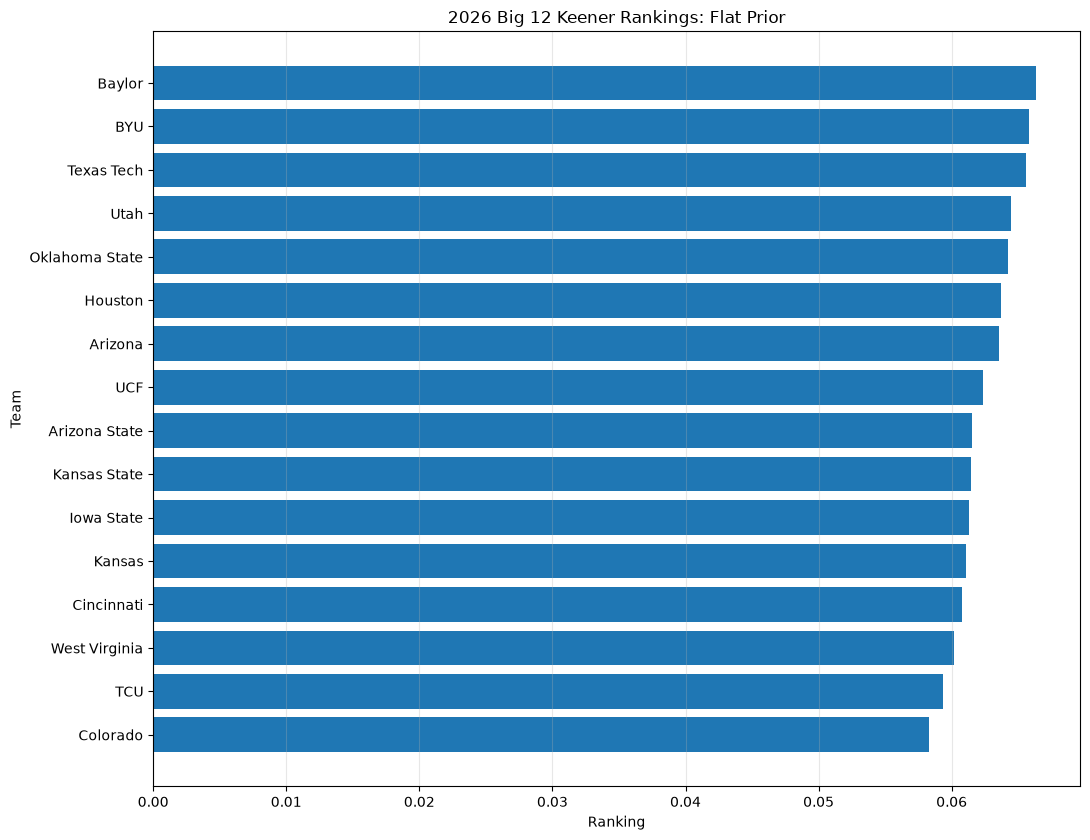

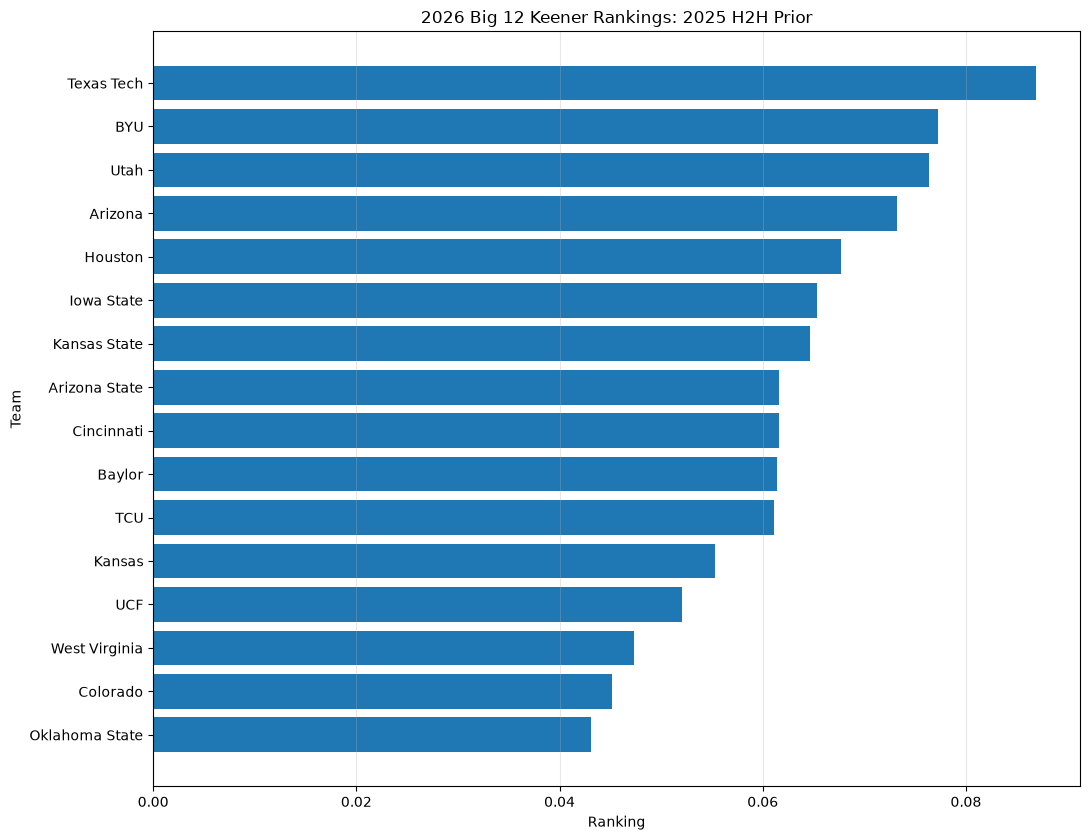

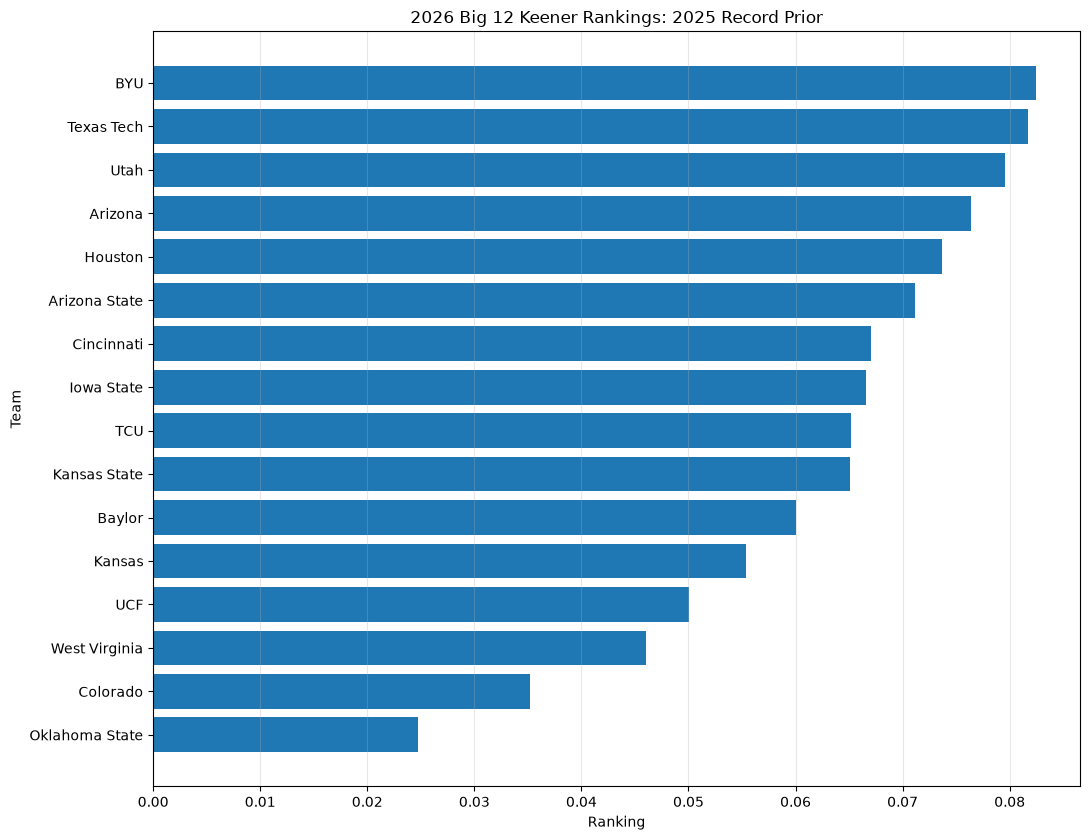


EIGENVALUE RESULTS
            Prior  lambda*  |lambda2 / lambda*|
       Flat Prior 0.499233             0.158985
   2025 H2H Prior 0.481875             0.159949
2025 Record Prior 0.467827             0.169684


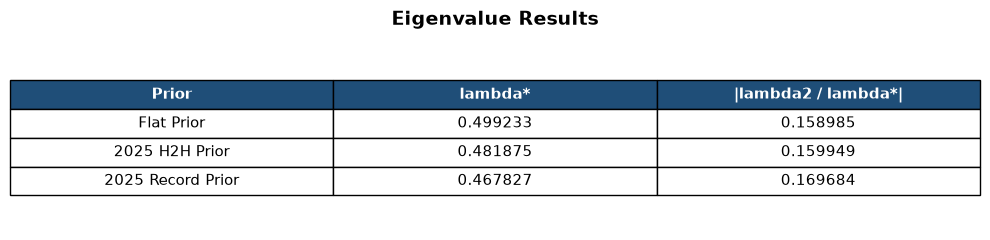

In [20]:
#bar charts
for name, result in results.items():
    ranking = pd.DataFrame({
        "Team": teams,
        "Ranking": result["r"]
    })

    ranking = ranking.sort_values(
        "Ranking",
        ascending=True
    )

    plt.figure(figsize=(11, 8.5))

    plt.barh(
        ranking["Team"],
        ranking["Ranking"],
        color="#1f77b4"
    )

    plt.xlabel("Ranking")
    plt.ylabel("Team")
    plt.title(f"2026 Big 12 Keener Rankings: {name}")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()

    filename = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    lambda_table = pd.DataFrame({
    "Prior": list(results.keys()),
    "lambda*": [
        results[name]["lambda_star"]
        for name in results
    ],
    "|lambda2 / lambda*|": [
        results[name]["ratio"]
        for name in results
    ]
})

lambda_table["lambda*"] = lambda_table["lambda*"].round(6)
lambda_table["|lambda2 / lambda*|"] = (
    lambda_table["|lambda2 / lambda*|"].round(6)
)

print("\nEIGENVALUE RESULTS")
print(lambda_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.axis("off")

table = ax.table(
    cellText=lambda_table.values,
    colLabels=lambda_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)

for column in range(len(lambda_table.columns)):
    table[(0, column)].set_facecolor("#1f4e78")
    table[(0, column)].set_text_props(
        color="white",
        weight="bold"
    )

plt.title(
    "Eigenvalue Results",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "eigenvalue_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
#predictions
prediction_games = data[
    (data["season"] == 2026)
    & (
        data["date"].isin([
            pd.Timestamp("2026-10-10"),
            pd.Timestamp("2026-10-11")
        ])
    )
].copy()

all_predictions = []

for prior_name, result in results.items():
    r = result["r"]

    for _, game in prediction_games.iterrows():
        home = game["home"]
        away = game["away"]

        home_ranking = r[team_index[home]]
        away_ranking = r[team_index[away]]

        if home_ranking > away_ranking:
            predicted_winner = home
        else:
            predicted_winner = away

        all_predictions.append({
            "Prior": prior_name,
            "Date": game["date"].date(),
            "Away": away,
            "Home": home,
            "Predicted Winner": predicted_winner
        })

predictions = pd.DataFrame(all_predictions)

print("\nOct. 10-11 Predictions")
print(predictions.to_string(index=False))


Oct. 10-11 Predictions
            Prior       Date       Away           Home Predicted Winner
       Flat Prior 2026-10-10 Iowa State            BYU              BYU
       Flat Prior 2026-10-11     Kansas           Utah             Utah
       Flat Prior 2026-10-10        UCF Oklahoma State   Oklahoma State
       Flat Prior 2026-10-10    Houston   Kansas State          Houston
       Flat Prior 2026-10-10    Arizona  West Virginia          Arizona
   2025 H2H Prior 2026-10-10 Iowa State            BYU              BYU
   2025 H2H Prior 2026-10-11     Kansas           Utah             Utah
   2025 H2H Prior 2026-10-10        UCF Oklahoma State              UCF
   2025 H2H Prior 2026-10-10    Houston   Kansas State          Houston
   2025 H2H Prior 2026-10-10    Arizona  West Virginia          Arizona
2025 Record Prior 2026-10-10 Iowa State            BYU              BYU
2025 Record Prior 2026-10-11     Kansas           Utah             Utah
2025 Record Prior 2026-10-10        UCF 


Prediction Results
            Prior       Date       Away           Home Predicted Winner  Actual Winner  Correct
       Flat Prior 2026-10-10 Iowa State            BYU              BYU            BYU     True
       Flat Prior 2026-10-11     Kansas           Utah             Utah           Utah     True
       Flat Prior 2026-10-10        UCF Oklahoma State   Oklahoma State Oklahoma State     True
       Flat Prior 2026-10-10    Houston   Kansas State          Houston        Houston     True
       Flat Prior 2026-10-10    Arizona  West Virginia          Arizona        Arizona     True
   2025 H2H Prior 2026-10-10 Iowa State            BYU              BYU            BYU     True
   2025 H2H Prior 2026-10-11     Kansas           Utah             Utah           Utah     True
   2025 H2H Prior 2026-10-10        UCF Oklahoma State              UCF Oklahoma State    False
   2025 H2H Prior 2026-10-10    Houston   Kansas State          Houston        Houston     True
   2025 H2H Prior 20

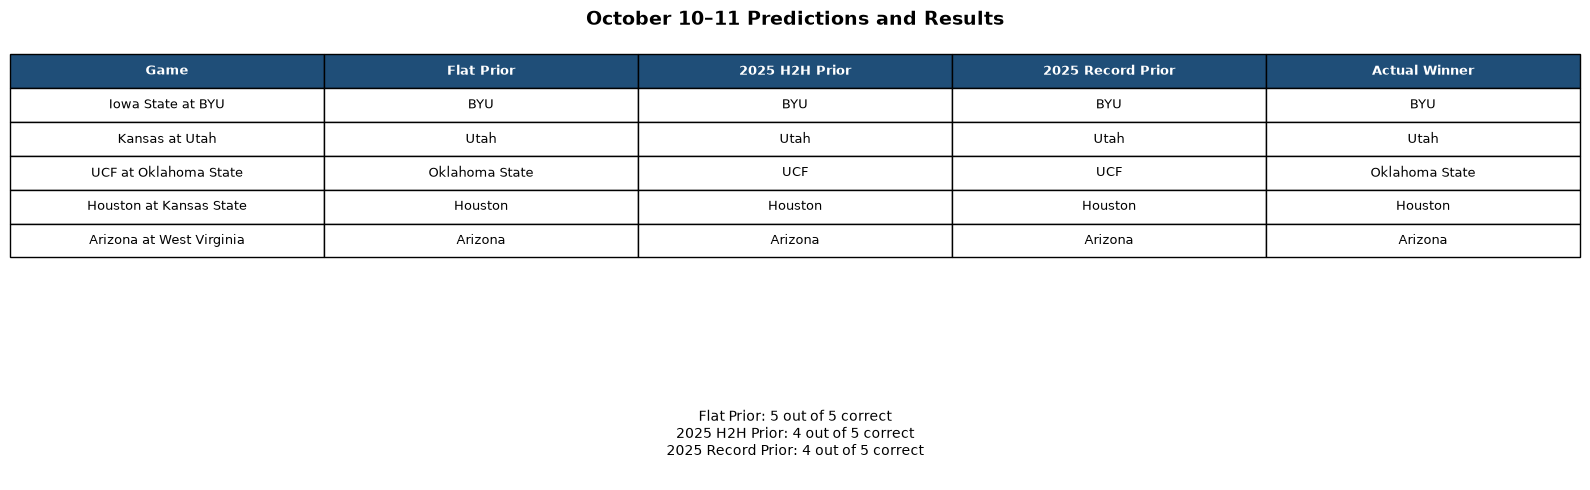

In [21]:
#grades:
if prediction_games["completed"].eq(1).all():
    actual_winners = {}

    for _, game in prediction_games.iterrows():
        matchup = (
            game["date"].date(),
            game["away"],
            game["home"]
        )

        if game["home_pts"] > game["away_pts"]:
            actual_winners[matchup] = game["home"]
        else:
            actual_winners[matchup] = game["away"]

    predictions["Actual Winner"] = predictions.apply(
        lambda row: actual_winners[
            (row["Date"], row["Away"], row["Home"])
        ],
        axis=1
    )

    predictions["Correct"] = (
        predictions["Predicted Winner"]
        == predictions["Actual Winner"]
    )

    print("\nPrediction Results")
    print(predictions.to_string(index=False))

    accuracy = predictions.groupby("Prior")["Correct"].agg(
        ["sum", "count"]
    )

    print("\nCorrect Predictions by Prior")
    print(accuracy)

else:
    print(
        "\nThe Oct. 10-11 games are not marked completed yet. "
        "Rerun fetch_big12.py after the games, then run this code again."
    )

prediction_games = data[
    (data["season"] == 2026)
    & (
        data["date"].isin([
            pd.Timestamp("2026-10-10"),
            pd.Timestamp("2026-10-11")
        ])
    )
].copy()

prediction_rows = []

for _, game in prediction_games.iterrows():
    home = game["home"]
    away = game["away"]

    row = {
        "Game": f"{away} at {home}"
    }

    for prior_name, result in results.items():
        r = result["r"]

        if r[team_index[home]] > r[team_index[away]]:
            row[prior_name] = home
        else:
            row[prior_name] = away

    if game["home_pts"] > game["away_pts"]:
        row["Actual Winner"] = home
    else:
        row["Actual Winner"] = away

    prediction_rows.append(row)

prediction_table = pd.DataFrame(prediction_rows)

print("\nPREDICTED AND ACTUAL WINNERS")
print(prediction_table.to_string(index=False))

print("\nPREDICTION ACCURACY")

for prior_name in results:
    correct = (
        prediction_table[prior_name]
        == prediction_table["Actual Winner"]
    ).sum()

    print(
        f"{prior_name}: "
        f"{correct} out of {len(prediction_table)} correct"
    )

accuracy_text = []

for prior_name in results:
    correct = (
        prediction_table[prior_name]
        == prediction_table["Actual Winner"]
    ).sum()

    accuracy_text.append(
        f"{prior_name}: {correct} out of "
        f"{len(prediction_table)} correct"
    )

fig, ax = plt.subplots(figsize=(16, 5))
ax.axis("off")

table = ax.table(
    cellText=prediction_table.values,
    colLabels=prediction_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="upper center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

for column in range(len(prediction_table.columns)):
    table[(0, column)].set_facecolor("#1f4e78")
    table[(0, column)].set_text_props(
        color="white",
        weight="bold"
    )

plt.title(
    "October 10–11 Predictions and Results",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.figtext(
    0.5,
    0.08,
    "\n".join(accuracy_text),
    ha="center",
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "prediction_results_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()